# Predicting Total Spend with Random Forest and XGBoost
**Bakari Kerr**

This notebook compares Random Forest and XGBoost regressors using the team's saved total-spend training/validation split. Four fixed experiments separate model choice from target scale: each model is fitted to raw spend and to `log1p(spend)`. No hyperparameter search, cross-validation tuning, or early stopping is performed.

The design follows the total-spend analysis in `AbhiramSegu_CPE_Linear_Regression.ipynb`. Baselines, dollar-scale evaluation, error diagnostics, and permutation importance support the comparison. Results are generated by the code; no performance conclusions are assumed in advance.

The saved split represents older versus newer campaigns, not a verified H1/H2 final test. Repeated comparison on this validation set is exploratory.


In [ ]:
%pip install -q pandas numpy scikit-learn xgboost matplotlib


## 1. Data and reproducibility

The inputs are the four CSVs in `data/spend_train_val_split/`. The reference notebook exported raw `total_spend` labels and 72 encoded planning-candidate features, including product, advertiser, geography, specialty, campaign size, calendar fields, and logged target-list size. Its split contained 332 training rows and 82 validation rows.

The loader supports execution from the repository root, `notebooks/`, or a Colab session with the four CSVs uploaded. `DATA_DIR` can also point to a mounted Drive folder. Libraries and fixed model settings are printed to make the run reproducible. No source files or split files are modified.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_DIR = None  # Optional: Path('/content/drive/MyDrive/spend_train_val_split')
FILES = ['X_train.csv', 'X_val.csv', 'y_train.csv', 'y_val.csv']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
if DATA_DIR is None:
    candidates = [Path.cwd() / 'data/spend_train_val_split',
                  Path.cwd().parent / 'data/spend_train_val_split', Path.cwd()]
    DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in FILES)), None)
if DATA_DIR is None and 'google.colab' in sys.modules:
    from google.colab import files
    print('Upload the four CSVs from data/spend_train_val_split (not the CPE split).')
    files.upload()
    DATA_DIR = Path.cwd()
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing the four spend split CSVs.')
DATA_DIR = Path(DATA_DIR)
missing = [f for f in FILES if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing files in {DATA_DIR}: {missing}')
X_train = pd.read_csv(DATA_DIR / 'X_train.csv')
X_val = pd.read_csv(DATA_DIR / 'X_val.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv')['total_spend']
y_val = pd.read_csv(DATA_DIR / 'y_val.csv')['total_spend']
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)
assert X_train.columns.equals(X_val.columns) and X_train.columns.is_unique
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_val.dtypes)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_val.to_numpy()).all()
assert np.isfinite(y_train).all() and np.isfinite(y_val).all()
assert y_train.ge(0).all() and y_val.ge(0).all()
forbidden = {'total_spend', 'log_total_spend', 'actual_spend_per_engagement',
             'log_actual_spend_per_engagement', 'spend_per_NRx_lift', 'spend_near_zero'}
assert not (set(X_train) & forbidden), 'Target-derived input detected.'
print(f'Training: {X_train.shape}; validation: {X_val.shape}; target: raw total_spend')
print(f'pandas {pd.__version__}; numpy {np.__version__}; sklearn {sklearn.__version__}; xgboost {xgboost.__version__}')
print('Input columns:', X_train.columns.tolist())


Training: (332, 72); validation: (82, 72); target: raw total_spend
pandas 3.1.0; numpy 2.5.4; sklearn 1.9.1; xgboost 3.4.1
Input columns: ['start_year', 'start_month', 'log_target_list', 'company_ADC THERAPEUTICS', 'company_AMGEN', 'company_ASTELLAS', 'company_ASTRAZENECA', 'company_BOEHRINGER INGELHEIM', 'company_BRISTOL MYERS SQUIBB', 'company_DAY ONE BIOPHARMACEUTICALS', 'company_EISAI', 'company_EMD SERONO', 'company_FERRING', 'company_GILEAD', 'company_GSK', 'company_HORIZON', 'company_JANSSEN', 'company_JAZZ PHARMACEUTICALS', 'company_LILLY', 'company_MERCK', 'company_NEUROCRINE', 'company_NOVARTIS', 'company_NOVO NORDISK', 'company_PFIZER', 'company_PROACT', 'company_RIGEL', 'company_SEAGEN', 'company_SERVIER', 'company_STEMLINE', 'company_TAKEDA', 'company_VIIV HEALTHCARE', 'sub_product_name_BRAND INTERCEPT', 'sub_product_name_BRAND PLAY', 'sub_product_name_BRANDSPOT', 'sub_product_name_BRANDSTORY', 'sub_product_name_CONDITION MESSAGE', 'sub_product_name_DIRECT MAIL', 'sub_prod

## 2. Spend distribution and evaluation coverage

Raw and logged training distributions describe the scale of the prediction problem. Large campaigns remain in the analysis. Logging uses `log1p`, which accepts zero spend.

MAPE is reported only for actual spend of at least $1,000, following the team's existing convention. This threshold is fixed across models; dollar MAE, RMSE, and R-squared include all rows. The coverage table makes the excluded rows explicit. The threshold is a team evaluation convention, not a requirement stated in the project brief.


,train,validation
all rows,332,82
zero spend,1,1
excluded from percentage metrics,6,2
percentage metric rows,326,80


,train,validation
count,3.320000e+02,8.200000e+01
mean,1.517009e+09,7.337879e+08
std,4.356438e+09,1.494806e+09
min,0.000000e+00,0.000000e+00
50%,1.831230e+08,8.373081e+07
90%,3.492377e+09,2.386338e+09
99%,2.367090e+10,6.942688e+09
max,3.905186e+10,7.130260e+09


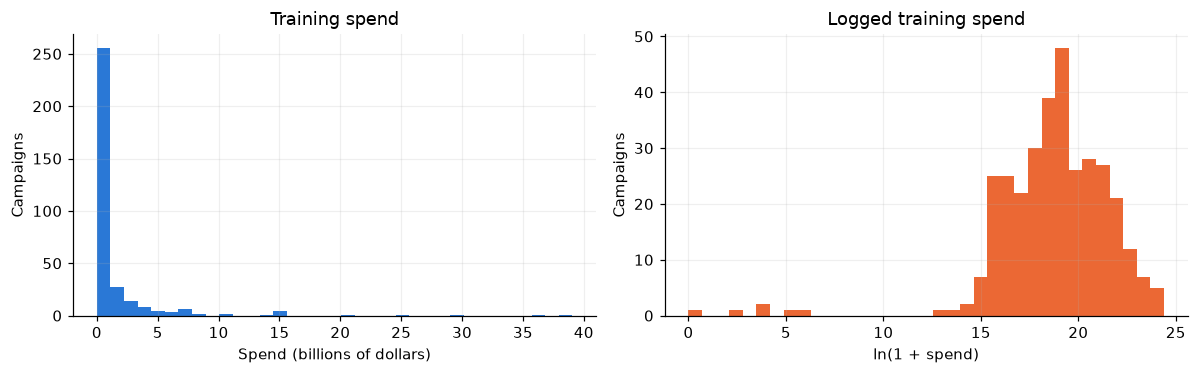

In [2]:
MAPE_MIN_SPEND = 1000.0
coverage = pd.DataFrame({
    'train': [len(y_train), int(y_train.eq(0).sum()), int(y_train.lt(MAPE_MIN_SPEND).sum()),
              int(y_train.ge(MAPE_MIN_SPEND).sum())],
    'validation': [len(y_val), int(y_val.eq(0).sum()), int(y_val.lt(MAPE_MIN_SPEND).sum()),
                   int(y_val.ge(MAPE_MIN_SPEND).sum())]
}, index=['all rows', 'zero spend', 'excluded from percentage metrics', 'percentage metric rows'])
display(coverage)
display(pd.concat([y_train.describe(percentiles=[.5, .9, .99]).rename('train'),
                   y_val.describe(percentiles=[.5, .9, .99]).rename('validation')], axis=1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(y_train / 1e9, bins=35, color='#2a78d6')
axes[0].set(xlabel='Spend (billions of dollars)', ylabel='Campaigns', title='Training spend')
axes[1].hist(np.log1p(y_train), bins=35, color='#eb6834')
axes[1].set(xlabel='ln(1 + spend)', ylabel='Campaigns', title='Logged training spend')
plt.tight_layout(); plt.show()


## 3. Shared scoring

All predictions are evaluated in dollars. Negative predictions are clipped to zero as a fixed nonnegative-spend rule, and their original count is reported. Clipping is applied identically to every model. R-squared and dollar errors use all rows; MAPE, within-30%, typical factor off, and within-2x use the same spend-at-least-$1,000 subset.

A factor of 2 means a prediction is twice or half the actual spend. A zero prediction for positive actual spend receives infinite factor error rather than being silently omitted. Log-scale R-squared is supplementary; it does not replace the project's dollar-scale R-squared. The brief's reference goals are MAPE below 30% and R-squared above 0.55 on held-out H2 data, which this exploratory split does not establish.


In [3]:
def nonnegative(pred):
    pred = np.asarray(pred, dtype=float)
    if not np.isfinite(pred).all():
        raise ValueError('Nonfinite predictions; inspect model output before scoring.')
    return np.maximum(pred, 0)

def evaluate(actual, pred):
    actual, pred = np.asarray(actual, dtype=float), nonnegative(pred)
    assert actual.shape == pred.shape
    keep = actual >= MAPE_MIN_SPEND
    result = {'MAE ($)': mean_absolute_error(actual, pred),
              'RMSE ($)': np.sqrt(mean_squared_error(actual, pred)),
              'R2': r2_score(actual, pred),
              'log R2': r2_score(np.log1p(actual), np.log1p(pred)),
              'MAPE rows': int(keep.sum())}
    if keep.any():
        a, p = actual[keep], pred[keep]
        relative = np.abs(a - p) / a
        factor = np.full(len(a), np.inf)
        positive = p > 0
        factor[positive] = np.maximum(p[positive] / a[positive], a[positive] / p[positive])
        result.update({'MAPE (%)': relative.mean() * 100,
                       'within 30% (%)': np.mean(relative <= .30) * 100,
                       'typical factor off': np.median(factor),
                       'within 2x (%)': np.mean(factor <= 2) * 100})
    else:
        result.update({k: np.nan for k in ['MAPE (%)', 'within 30% (%)',
                                            'typical factor off', 'within 2x (%)']})
    return result

results, predictions, models, train_predictions = [], {}, {}, {}
def record(name, raw_pred, notes=''):
    raw_pred = np.asarray(raw_pred, dtype=float)
    predictions[name] = nonnegative(raw_pred)
    results.append({'experiment': name, **evaluate(y_val, raw_pred),
                    'negative before clipping': int((raw_pred < 0).sum()), 'notes': notes})
    display(pd.DataFrame(results[-1:]).round(4))


## 4. Training-only baselines

The mean and median baselines predict one training-derived value for every validation row. The product baseline uses training medians within sub-product groups and falls back to the overall median for an unseen group.

The supplied encoding drops a reference category. An all-zero sub-product block is therefore treated as the reference-or-unseen group; the CSVs cannot distinguish those cases. This grouping reproduces the available encoded information without assuming that the reference column exists.


In [4]:
record('B0 Training mean', np.full(len(y_val), y_train.mean()))
record('B1 Training median', np.full(len(y_val), y_train.median()))
product_cols = [c for c in X_train if c.startswith('sub_product_name_')]
assert product_cols

def product_group(X):
    block = X[product_cols]
    assert block.isin([0, 1]).all().all() and block.sum(axis=1).le(1).all()
    return block.idxmax(axis=1).where(block.sum(axis=1).gt(0), 'REFERENCE_OR_UNSEEN')

product_train, product_val = product_group(X_train), product_group(X_val)
product_medians = y_train.groupby(product_train).median()
record('B2 Product median', product_val.map(product_medians).fillna(y_train.median()).to_numpy(),
       'Encoded reference and unseen products cannot be distinguished')


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,B0 Training mean,1.471931e+09,1.679474e+09,-0.2779,-0.7435,80,6619.6183,5.0,17.0038,11.25,0,


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,B1 Training median,7.183268e+08,1.584433e+09,-0.1374,-0.0663,80,766.6825,7.5,5.1306,16.25,0,


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,B2 Product median,7.040241e+08,1.580958e+09,-0.1324,-0.0223,80,693.8272,8.75,5.1508,20.0,0,Encoded reference and unseen products cannot b...


## 5. Four fixed tree-model experiments

Random Forest averages independently fitted trees. XGBoost adds trees sequentially to correct the current model's errors. Both use the same saved inputs and validation rows; feature scaling is unnecessary for these tree models.

Each model uses one explicit configuration chosen before evaluation: 300 trees for each; Random Forest uses unrestricted depth and all features at each split, while XGBoost uses depth 3 and learning rate 0.05. Equal tree counts do not imply equal model complexity. These settings are reproducible starting choices, not tuned optima or a claim about the best version of either algorithm.

Raw and logged versions of a model have identical settings. The logged models minimize squared error in log space; inverse transformation does not automatically yield an unbiased conditional mean in dollars. No bias correction is fitted here. No validation data is passed to model fitting or early stopping.


In [5]:
RF_PARAMS = dict(n_estimators=300, max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, max_features=1.0, bootstrap=True,
                 random_state=RANDOM_STATE, n_jobs=-1)
XGB_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.05,
                  min_child_weight=1, subsample=1.0, colsample_bytree=1.0,
                  reg_alpha=0.0, reg_lambda=1.0, objective='reg:squarederror',
                  tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1)
print('Random Forest:', RF_PARAMS)
print('XGBoost:', XGB_PARAMS)

def to_dollars(pred, log_target):
    pred = np.asarray(pred, dtype=float)
    if log_target:
        with np.errstate(over='raise', invalid='raise'):
            pred = np.expm1(pred)
    return pred

experiments = [
    ('E1 Random Forest raw', RandomForestRegressor(**RF_PARAMS), False),
    ('E2 XGBoost raw', XGBRegressor(**XGB_PARAMS), False),
    ('E3 Random Forest log', RandomForestRegressor(**RF_PARAMS), True),
    ('E4 XGBoost log', XGBRegressor(**XGB_PARAMS), True),
]
# Makes this cell safe to rerun after the baselines without duplicating model rows.
results[:] = [r for r in results if not r['experiment'].startswith('E')]
for name, model, log_target in experiments:
    target = np.log1p(y_train) if log_target else y_train
    model.fit(X_train, target)
    models[name] = (model, log_target)
    train_predictions[name] = nonnegative(to_dollars(model.predict(X_train), log_target))
    raw_pred = to_dollars(model.predict(X_val), log_target)
    record(name, raw_pred, 'Fixed settings; log1p target' if log_target else 'Fixed settings; raw target')


Random Forest: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'bootstrap': True, 'random_state': 42, 'n_jobs': -1}
XGBoost: {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': -1}


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,E1 Random Forest raw,5.452627e+08,1.440115e+09,0.0604,0.2158,80,221.8,17.5,2.2519,41.25,0,Fixed settings; raw target


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,E2 XGBoost raw,7.584357e+08,2.451302e+09,-1.7224,0.001,80,555.2943,16.25,2.4848,40.0,0,Fixed settings; raw target


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,E3 Random Forest log,4.256490e+08,9.900946e+08,0.5559,0.3471,80,106.8491,22.5,1.8606,55.0,0,Fixed settings; log1p target


,experiment,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
0,E4 XGBoost log,4.486391e+08,1.130795e+09,0.4207,0.3771,80,124.6674,20.0,1.7996,58.75,0,Fixed settings; log1p target


## 6. Overall comparison and fitting gap

The results table compares baselines and all four experiments. Training and validation errors describe the fitting gap: a low training error with much higher validation error can indicate overfitting or differences between older and newer campaigns.

MAPE is the primary comparison metric, with dollar-scale R-squared and errors providing context. Better validation results identify a promising fixed experiment, not an independently confirmed final winner.


,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping,notes
experiment,,,,,,,,,,,
B0 Training mean,1.471931e+09,1.679474e+09,-0.2779,-0.7435,80,6619.6183,5.00,17.0038,11.25,0,
B1 Training median,7.183268e+08,1.584433e+09,-0.1374,-0.0663,80,766.6825,7.50,5.1306,16.25,0,
B2 Product median,7.040241e+08,1.580958e+09,-0.1324,-0.0223,80,693.8272,8.75,5.1508,20.00,0,Encoded reference and unseen products cannot b...
E1 Random Forest raw,5.452627e+08,1.440115e+09,0.0604,0.2158,80,221.8000,17.50,2.2519,41.25,0,Fixed settings; raw target
E2 XGBoost raw,7.584357e+08,2.451302e+09,-1.7224,0.0010,80,555.2943,16.25,2.4848,40.00,0,Fixed settings; raw target
E3 Random Forest log,4.256490e+08,9.900946e+08,0.5559,0.3471,80,106.8491,22.50,1.8606,55.00,0,Fixed settings; log1p target
E4 XGBoost log,4.486391e+08,1.130795e+09,0.4207,0.3771,80,124.6674,20.00,1.7996,58.75,0,Fixed settings; log1p target


,train MAE ($),validation MAE ($),train MAPE (%),validation MAPE (%),train R2,validation R2
experiment,,,,,,
E1 Random Forest raw,3.493768e+08,5.452627e+08,69.9000,221.8000,0.9329,0.0604
E2 XGBoost raw,2.483920e+08,7.584357e+08,240.3296,555.2943,0.9895,-1.7224
E3 Random Forest log,3.522989e+08,4.256490e+08,30.9145,106.8491,0.8975,0.5559
E4 XGBoost log,6.491366e+08,4.486391e+08,64.2974,124.6674,0.6892,0.4207


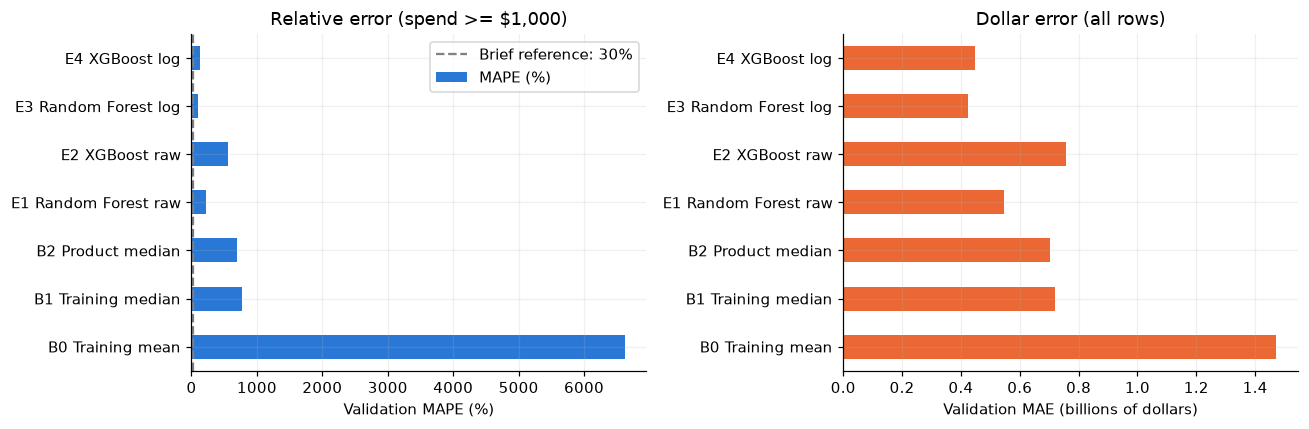

In [6]:
results_df = pd.DataFrame(results).set_index('experiment')
display(results_df.round(4))
gaps = []
for name in models:
    tr = evaluate(y_train, train_predictions[name])
    va = evaluate(y_val, predictions[name])
    gaps.append({'experiment': name, 'train MAE ($)': tr['MAE ($)'],
                 'validation MAE ($)': va['MAE ($)'], 'train MAPE (%)': tr['MAPE (%)'],
                 'validation MAPE (%)': va['MAPE (%)'], 'train R2': tr['R2'], 'validation R2': va['R2']})
display(pd.DataFrame(gaps).set_index('experiment').round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results_df['MAPE (%)'].plot.barh(ax=axes[0], color='#2a78d6')
axes[0].axvline(30, ls='--', color='gray', label='Brief reference: 30%')
axes[0].set(xlabel='Validation MAPE (%)', ylabel='', title='Relative error (spend >= $1,000)')
axes[0].legend()
results_df['MAE ($)'].div(1e9).plot.barh(ax=axes[1], color='#eb6834')
axes[1].set(xlabel='Validation MAE (billions of dollars)', ylabel='', title='Dollar error (all rows)')
plt.tight_layout(); plt.show()


## 7. Prediction and error diagnostics

All four models are shown rather than selecting plots only for the best validation result. Predicted-versus-actual plots use `log10(1 + spend)` so zero and very large values remain visible. The diagonal represents exact predictions.

Spend-range tables report counts alongside errors. The largest mistakes identify campaigns that most affect dollar error; they do not establish that the records are incorrect. The saved row number links back to the validation CSV, not an independently verified campaign ID.


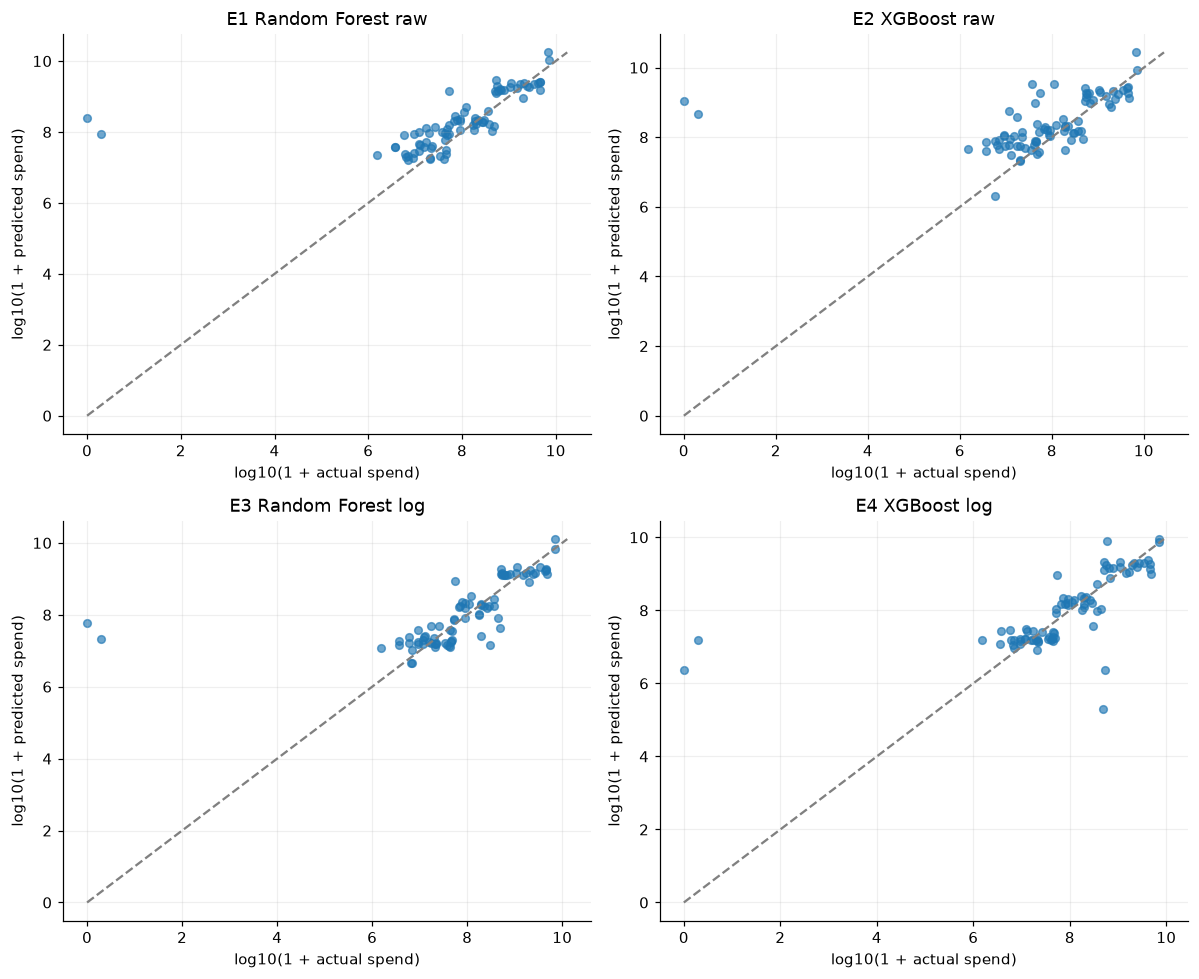

E1 Random Forest raw


,spend range,rows,MAE ($),MAPE (%)
0,below $1k,2,1.694552e+08,NaN
1,$1m to $100m,42,8.369991e+07,343.949
2,$100m to $1bn,23,4.736786e+08,108.932
3,$1bn and above,15,1.997508e+09,52.847


,validation_row,actual,predicted,product_group,residual,absolute_error
48,48,6.898690e+09,1.758778e+10,REFERENCE_OR_UNSEEN,-1.068909e+10,1.068909e+10
3,3,7.130260e+09,1.076973e+10,sub_product_name_EMAIL ALERT,-3.639471e+09,3.639471e+09
28,28,4.724469e+09,1.568337e+09,sub_product_name_EMAIL ALERT,3.156132e+09,3.156132e+09
47,47,5.190420e+08,2.969483e+09,REFERENCE_OR_UNSEEN,-2.450441e+09,2.450441e+09
46,46,4.559207e+09,2.491917e+09,REFERENCE_OR_UNSEEN,2.067290e+09,2.067290e+09


E2 XGBoost raw


,spend range,rows,MAE ($),MAPE (%)
0,below $1k,2,7.688333e+08,NaN
1,$1m to $100m,42,2.158645e+08,916.698
2,$100m to $1bn,23,5.659752e+08,216.737
3,$1bn and above,15,2.571355e+09,62.485


,validation_row,actual,predicted,product_group,residual,absolute_error
48,48,6.898690e+09,2.740769e+10,REFERENCE_OR_UNSEEN,-2.050900e+10,2.050900e+10
28,28,4.724469e+09,1.304878e+09,sub_product_name_EMAIL ALERT,3.419591e+09,3.419591e+09
30,30,3.681600e+07,3.391788e+09,sub_product_name_EMAIL ALERT,-3.354972e+09,3.354972e+09
38,38,1.092572e+08,3.272133e+09,sub_product_name_EMAIL ALERT,-3.162876e+09,3.162876e+09
33,33,4.527904e+09,1.851037e+09,sub_product_name_EMAIL ALERT,2.676867e+09,2.676867e+09


... (2 outputs left out)

,validation_row,actual,predicted,product_group,residual,absolute_error
48,48,6.898690e+09,1.273401e+10,REFERENCE_OR_UNSEEN,-5.835319e+09,5.835319e+09
28,28,4.724469e+09,1.403038e+09,sub_product_name_EMAIL ALERT,3.321431e+09,3.321431e+09
33,33,4.527904e+09,1.748668e+09,sub_product_name_EMAIL ALERT,2.779236e+09,2.779236e+09
46,46,4.559207e+09,1.866460e+09,REFERENCE_OR_UNSEEN,2.692747e+09,2.692747e+09
61,61,4.233486e+09,1.680046e+09,sub_product_name_EMAIL ALERT,2.553440e+09,2.553440e+09


E4 XGBoost log


,spend range,rows,MAE ($),MAPE (%)
0,below $1k,2,8.970556e+06,NaN
1,$1m to $100m,42,4.650585e+07,152.224
2,$100m to $1bn,23,6.560680e+08,129.507
3,$1bn and above,15,1.315177e+09,40.088


,validation_row,actual,predicted,product_group,residual,absolute_error
9,9,5.826184e+08,7.884676e+09,REFERENCE_OR_UNSEEN,-7.302058e+09,7.302058e+09
28,28,4.724469e+09,9.612255e+08,sub_product_name_EMAIL ALERT,3.763244e+09,3.763244e+09
46,46,4.559207e+09,1.345761e+09,REFERENCE_OR_UNSEEN,3.213446e+09,3.213446e+09
33,33,4.527904e+09,1.914267e+09,sub_product_name_EMAIL ALERT,2.613637e+09,2.613637e+09
48,48,6.898690e+09,8.943545e+09,REFERENCE_OR_UNSEEN,-2.044856e+09,2.044856e+09


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, models):
    a, p = np.log10(1 + y_val.to_numpy()), np.log10(1 + predictions[name])
    ax.scatter(a, p, alpha=.65, s=25)
    lo, hi = min(a.min(), p.min()), max(a.max(), p.max())
    ax.plot([lo, hi], [lo, hi], '--', color='gray')
    ax.set(title=name, xlabel='log10(1 + actual spend)', ylabel='log10(1 + predicted spend)')
plt.tight_layout(); plt.show()

diagnostics = {}
spend_bins = [-np.inf, 1000, 1e6, 1e8, 1e9, np.inf]
spend_labels = ['below $1k', '$1k to $1m', '$1m to $100m', '$100m to $1bn', '$1bn and above']
for name in models:
    d = pd.DataFrame({'validation_row': np.arange(len(y_val)), 'actual': y_val,
                       'predicted': predictions[name], 'product_group': product_val})
    d['residual'] = d.actual - d.predicted
    d['absolute_error'] = d.residual.abs()
    d['spend_range'] = pd.cut(d.actual, spend_bins, labels=spend_labels, right=False)
    diagnostics[name] = d
    print(name)
    rows = []
    for band, group in d.groupby('spend_range', observed=True):
        m = evaluate(group.actual, group.predicted)
        rows.append({'spend range': str(band), 'rows': len(group),
                     'MAE ($)': m['MAE ($)'], 'MAPE (%)': m['MAPE (%)']})
    display(pd.DataFrame(rows).round(3))
    display(d.nlargest(5, 'absolute_error').drop(columns='spend_range').round(3))


## 8. Permutation importance

Validation permutation importance measures the increase in MAE after an input is shuffled. It is computed for all four models on the same dollar-prediction scale, allowing a more consistent comparison than their different built-in importance definitions. It describes validation behavior and is not used to refit models or choose settings.

Correlated predictors can share importance. Shuffling individual category indicators can create invalid combinations, so these rankings are descriptive rather than causal. Importance is calculated in dollar MAE because it includes every validation row and stays stable at zero spend.


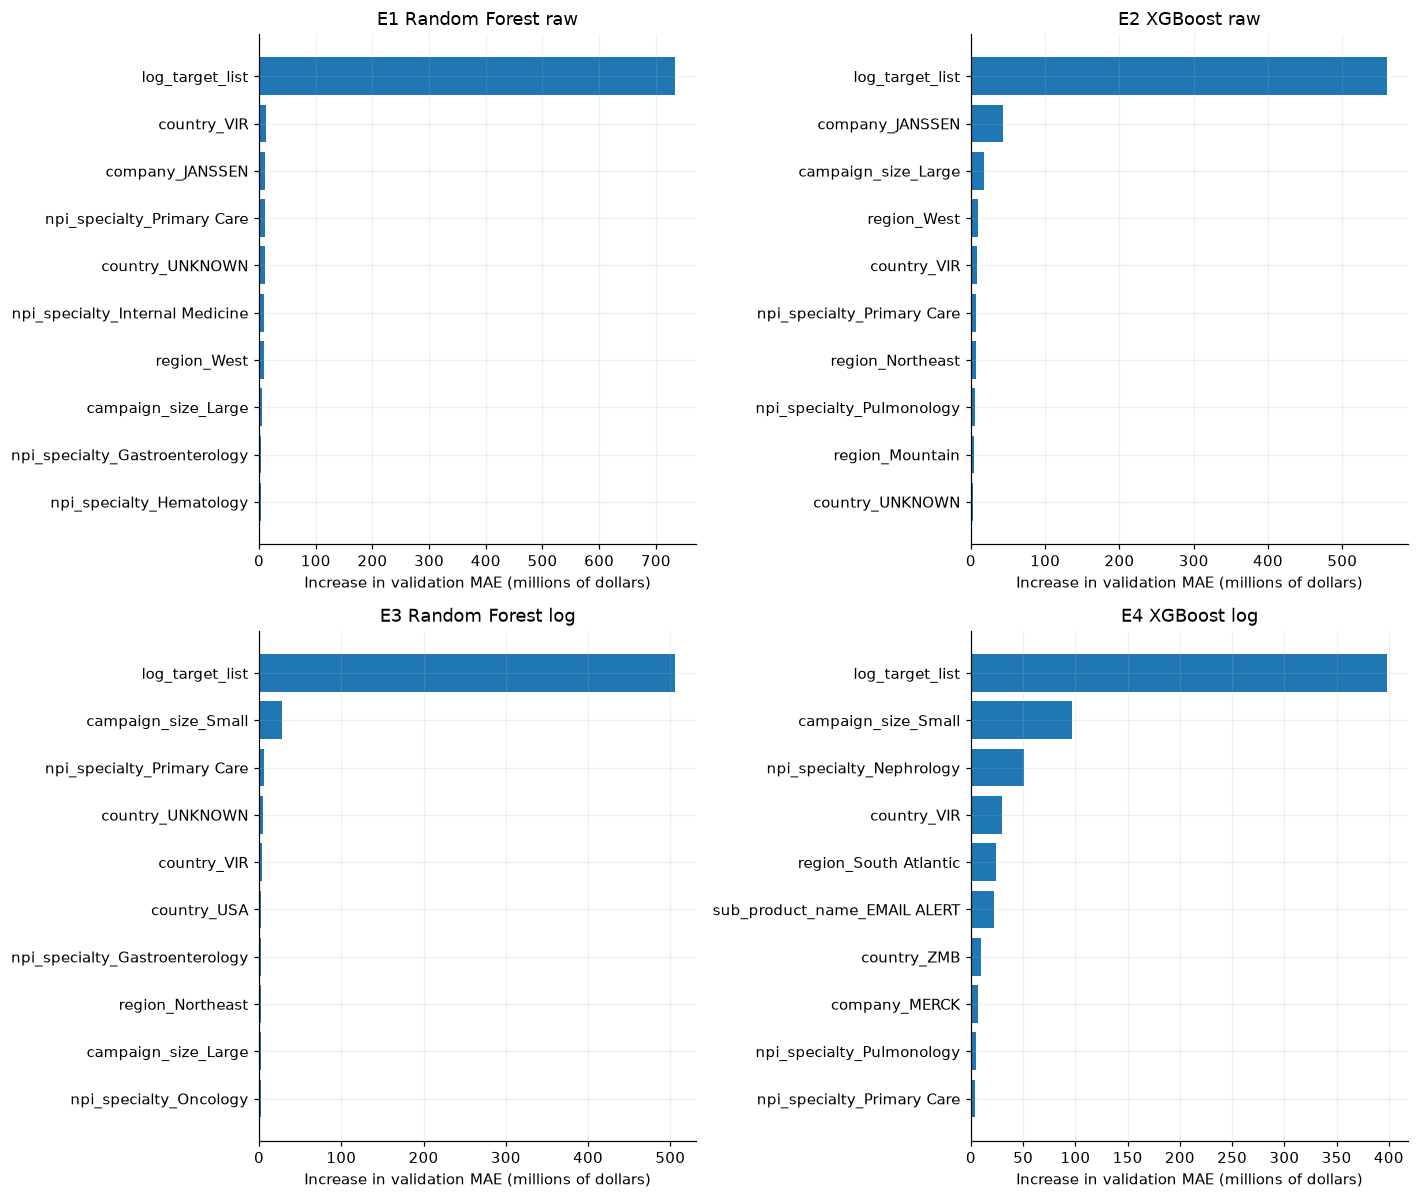

E1 Random Forest raw


,feature,MAE increase ($),std ($)
2,log_target_list,7.343153e+08,1.013979e+08
44,country_VIR,1.171343e+07,1.007207e+07
16,company_JANSSEN,1.107916e+07,8.528244e+06
57,npi_specialty_Primary Care,1.081781e+07,2.009639e+07
41,country_UNKNOWN,9.714114e+06,2.895159e+06
53,npi_specialty_Internal Medicine,9.241349e+06,8.778130e+06
68,region_West,8.661485e+06,1.296836e+07
69,campaign_size_Large,4.783117e+06,2.757518e+06
51,npi_specialty_Gastroenterology,4.178010e+06,5.395976e+06
52,npi_specialty_Hematology,3.660935e+06,7.568657e+05


E2 XGBoost raw


,feature,MAE increase ($),std ($)
2,log_target_list,5.604625e+08,1.301088e+08
16,company_JANSSEN,4.255216e+07,4.257442e+07
69,campaign_size_Large,1.787967e+07,4.039652e+06
68,region_West,9.712957e+06,2.321554e+07
44,country_VIR,8.147107e+06,1.646212e+07
57,npi_specialty_Primary Care,7.341616e+06,7.900300e+06
63,region_Northeast,6.672129e+06,1.323664e+07
58,npi_specialty_Pulmonology,4.891603e+06,2.994808e+06
62,region_Mountain,4.090217e+06,5.879966e+06
41,country_UNKNOWN,3.363434e+06,1.416239e+06


E3 Random Forest log


,feature,MAE increase ($),std ($)
2,log_target_list,5.061165e+08,9.423319e+07
71,campaign_size_Small,2.837925e+07,3.819586e+07
57,npi_specialty_Primary Care,6.606961e+06,3.484746e+06
41,country_UNKNOWN,4.891942e+06,2.800983e+06
44,country_VIR,3.382975e+06,3.086155e+06
42,country_USA,2.967846e+06,2.843359e+06
51,npi_specialty_Gastroenterology,2.521591e+06,3.257408e+06
63,region_Northeast,2.506884e+06,7.011510e+06
69,campaign_size_Large,2.129284e+06,1.990710e+06
56,npi_specialty_Oncology,2.112916e+06,1.384467e+06


E4 XGBoost log


,feature,MAE increase ($),std ($)
2,log_target_list,3.983954e+08,1.061270e+08
71,campaign_size_Small,9.691621e+07,7.882072e+07
54,npi_specialty_Nephrology,5.059915e+07,1.871571e+07
44,country_VIR,2.993001e+07,1.136896e+07
65,region_South Atlantic,2.413421e+07,1.254378e+07
37,sub_product_name_EMAIL ALERT,2.189841e+07,1.271828e+07
47,country_ZMB,9.518124e+06,1.829393e+07
19,company_MERCK,6.746455e+06,6.574754e+06
58,npi_specialty_Pulmonology,4.496928e+06,5.195411e+06
57,npi_specialty_Primary Care,3.927982e+06,4.460297e+06


In [8]:
class DollarMAEScorer:
    def __init__(self, log_target):
        self.log_target = log_target
    def __call__(self, estimator, X, y):
        pred = nonnegative(to_dollars(estimator.predict(X), self.log_target))
        return -mean_absolute_error(y, pred)

importance_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, (model, log_target)) in zip(axes.flat, models.items()):
    # Serial outer loop avoids nested parallelism; model prediction can use its own threads.
    perm = permutation_importance(model, X_val, y_val, scoring=DollarMAEScorer(log_target),
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
    table = pd.DataFrame({'feature': X_val.columns, 'MAE increase ($)': perm.importances_mean,
                          'std ($)': perm.importances_std}).sort_values('MAE increase ($)', ascending=False)
    importance_tables[name] = table
    top = table.head(10).iloc[::-1]
    ax.barh(top.feature, top['MAE increase ($)'] / 1e6)
    ax.set(title=name, xlabel='Increase in validation MAE (millions of dollars)')
plt.tight_layout(); plt.show()
for name, table in importance_tables.items():
    print(name)
    display(table.head(10).round(3))


## 9. Experiment report

The comparison isolates two modeling choices: Random Forest versus XGBoost, and raw versus logged spend. Each algorithm uses one fixed configuration; results do not represent a tuned comparison of the algorithms' maximum achievable performance.

The generated summary below reports the strongest validation MAPE among the four tree experiments and compares it with the baselines. All metrics remain in the full table so improvements in one metric can be weighed against deterioration in another. Lower MAPE does not necessarily imply lower dollar RMSE or higher R-squared.

Limitations include the small dataset, unknown categories represented by the reference encoding, unverified prediction-time availability and provenance of campaign-size/target-list fields, and the absence of a separately verified H2 test set. The reference notebook merged new descriptors using outcome columns as matching keys; the supplied CSVs alone do not establish how those descriptors were originally produced. Neither a strong correlation nor good validation performance demonstrates that a feature was known before launch.

Random Forest averages training outcomes within leaves and cannot extrapolate beyond their observed target range. XGBoost uses a different additive construction but is also limited by patterns represented in training. Logged models emphasize proportional differences and require care when interpreted as expected dollar totals. Predicting spend alone does not establish campaign ROI or prescription lift.


In [9]:
tree_results = results_df.loc[list(models)]
valid = tree_results['MAPE (%)'].dropna()
if len(valid):
    best_name = valid.idxmin()
    row = tree_results.loc[best_name]
    print(f'Lowest validation MAPE among fixed tree experiments: {best_name}')
    print(f'MAPE: {row["MAPE (%)"]:.2f}%; R2: {row["R2"]:.4f}; MAE: ${row["MAE ($)"]:,.0f}')
    best_baseline = results_df.loc[['B0 Training mean', 'B1 Training median', 'B2 Product median'], 'MAPE (%)'].min()
    print(f'Best baseline MAPE: {best_baseline:.2f}%')
    print('Below 30% MAPE on this validation split:', bool(row['MAPE (%)'] < 30))
    print('Above 0.55 dollar R2 on this validation split:', bool(row['R2'] > .55))
    print('This comparison is exploratory validation, not a final held-out H2 evaluation.')
else:
    print('No validation rows meet the percentage-metric threshold.')
# Optional exports; disabled so running the notebook does not write additional files.
# results_df.to_csv('BakariKerr_TS_Tree_Models_results.csv')
# for name, frame in diagnostics.items():
#     frame.to_csv(name.replace(' ', '_') + '_validation_predictions.csv', index=False)


Lowest validation MAPE among fixed tree experiments: E3 Random Forest log
MAPE: 106.85%; R2: 0.5559; MAE: $425,649,004
Best baseline MAPE: 693.83%
Below 30% MAPE on this validation split: False
Above 0.55 dollar R2 on this validation split: True
This comparison is exploratory validation, not a final held-out H2 evaluation.
